First we need a way to simulate from the distribution of $f$. To do so we use the accept / reject method, and numerical integraion of the constant depending on $\theta$

C:\Users\thoma\AppData\Local\Temp\ipykernel_23512\275057294.py:9: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  c = quad(c, 0, np.inf)[0]


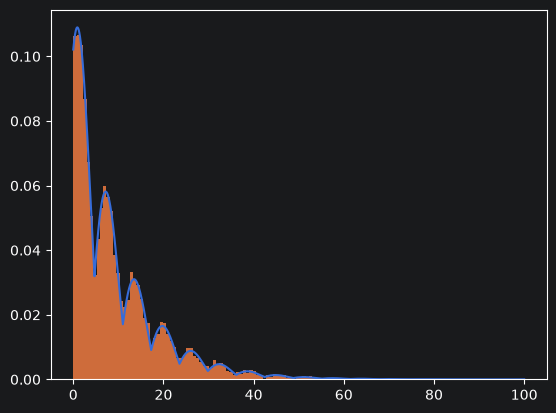

In [1]:
from scipy.integrate import quad
import numpy as np
from scipy.stats import expon
theta = 0.1

def c(theta):
    # Compute the constant using quadrature
    c = lambda x : (1 + np.sqrt(1 + np.sin(x)))*np.exp(-theta*x)
    c = quad(c, 0, np.inf)[0]
    return c

def draw_samples(theta, n_samples = 20):
    # Simulate from Exponential and use Accept/Reject Method to sample from f:


    samples = np.zeros(n_samples)

    # Compute the pdf of f and the dominating function
    constant = (1 + np.sqrt(2)) / (c(theta) * theta)
    i = 0
    c_theta = c(theta)
    def pdf(x):
        return 1 / c_theta * ( 1 + np.sqrt(1 + np.sin(x)))*np.exp(-theta*x)

    f_star = lambda x: pdf(x) / (constant * expon.pdf(x, scale= 1 / theta))

    # Accept reject logic
    while i < n_samples:
        Y = np.random.exponential( scale =  1 / theta)
        U = np.random.uniform(0, 1)
        if U < f_star(Y):
            samples[i] = Y
            i += 1
    return samples

samples = draw_samples(theta, n_samples = 10000)

xx = np.linspace(0, 100, 10000)
import matplotlib.pyplot as plt

plt.plot(xx, 1 / c(theta) * ( 1 + np.sqrt(1 + np.sin(xx)))*np.exp(-theta*xx))
plt.hist(samples, density=True, bins = 100)
plt.show()
# Compute constant

# Draw samples

In [27]:

data = draw_samples(theta, n_samples = 2000)
x_bar = np.mean(data)
# Compute the derivative of the log of f(X, theta) - Use that we were given this in section 9.
h = lambda x, theta: -x + x_bar


# Use robbins monroe to find the root of the derivative as or MLE estimate
# We see that this converges to 0.1 as we increase the sample size.
sampler = lambda t : draw_samples(t, n_samples = 1)

from week10 import robbins_monro

a = [0.02/n**0.7 for n in range(1, 10000)]

theta_star = robbins_monro(
    h,
    sampler,
    1,
    a=a,
    tol= 10**-6,
    max_iter=5000,
    dist_depend=True
)

C:\Users\thoma\AppData\Local\Temp\ipykernel_23512\275057294.py:9: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  c = quad(c, 0, np.inf)[0]


Convergence at iteration 725
